# benchmark-figure
7.28.25

Calculate the MSEs and benchmark these puppies. 

In [1]:
import pandas as pd
import numpy as np
import sys
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../../../bin/")

from utils import mse_func 

# plotting templates
sns.set(context="talk", style="ticks") 
pal = sns.color_palette("tab10")

#### Configs

In [2]:
unimputed_report_full_path="../quant-reports/SMTG-DIANN-quants-report.csv"
unimputed_report_partitioned_path="../quant-reports/SMTG-holdout-unimputed-report.csv"
cortado_report_path="../quant-reports/SMTG-holdout-cortado-report.csv"
nettle_report_path="../quant-reports/SMTG-holdout-nettle-report.csv"

rowmeans_plugin_report_path="../plugin-reports/SMTG-holdout-rowmeans-imputed.csv"
colmin_plugin_report_path="../plugin-reports/SMTG-holdout-colmin-imputed.csv"
knn_plugin_report_path="../plugin-reports/SMTG-holdout-knn-imputed.csv"
mf_plugin_report_path="../plugin-reports/SMTG-holdout-missforest-imputed.csv"

#### Read in and pre-process the unimputed Skyline quants report 

In [3]:
unimputed_report = pd.read_csv(unimputed_report_full_path, low_memory=False)
# Pre-process
to_drop=["Protein Name", "Peptide Modified Sequence", "Precursor Charge"]

# Remove the decoy proteins
decoy_arr = unimputed_report["Protein Name"] == "Decoys"
unimputed_report = unimputed_report[~decoy_arr]

#  Reindex
unimputed_report.index = unimputed_report["Peptide Modified Sequence"]
unimputed_report = unimputed_report.drop(columns=to_drop)

# Trim the column names 
new_cols = [x.split(" ")[0].split("-")[-1] for x in unimputed_report.columns]
unimputed_report.columns = new_cols

print(unimputed_report.shape)
unimputed_report.head(4)

(125583, 66)


,HADT01,TRPR01,TZR02,TZR03,TZR04,TZR05,TZR06,TZR07,TZR08,TZR09,...,TZR53,TZR54,TZR55,TZR56,TZR57,TZR58,TZR59,TZR60,TZR61,TZR62
Peptide Modified Sequence,,,,,,,,,,,,,,,,,,,,,
VHIPDLSSFAMPLLDGDLEGSGK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TVFPFSYQESPPR,NaN,NaN,NaN,NaN,1073939.78,NaN,NaN,NaN,NaN,NaN,...,1341038.94,NaN,758285.69,1185013.88,NaN,426534.54,NaN,NaN,NaN,NaN
MSFSGIFR,NaN,NaN,NaN,413938.88,NaN,NaN,129489.38,NaN,NaN,NaN,...,546766.61,NaN,306818.95,NaN,NaN,NaN,491294.05,NaN,NaN,NaN
ESSPNSNPATSPGGIR,NaN,NaN,923883.34,934265.12,595447.66,910682.94,742352.97,422275.65,961113.22,NaN,...,951607.09,NaN,671797.02,NaN,886462.25,NaN,1121806.16,NaN,1285258.17,NaN


#### Read in the heldout, unimputed Skyline quants report 

In [4]:
unimputed_holdout_report = pd.read_csv(unimputed_report_partitioned_path, low_memory=False)
# Pre-process
to_drop=["Protein Name", "Peptide Modified Sequence", "Precursor Charge"]

# Remove the decoy proteins
decoy_arr = unimputed_holdout_report["Protein Name"] == "Decoys"
unimputed_holdout_report = unimputed_holdout_report[~decoy_arr]

#  Reindex
unimputed_holdout_report.index = unimputed_holdout_report["Peptide Modified Sequence"]
unimputed_holdout_report = unimputed_holdout_report.drop(columns=to_drop)

# Trim the column names 
new_cols = [x.split(" ")[0].split("-")[-1] for x in unimputed_holdout_report.columns]
unimputed_holdout_report.columns = new_cols

print(unimputed_holdout_report.shape)
unimputed_holdout_report.head(4)

(120995, 20)


,TZR02,TZR03,TZR04,TZR05,TZR16,TZR17,TZR18,TZR19,TZR29,TZR30,TZR31,TZR32,TZR43,TZR44,TZR45,TZR46,TZR59,TZR60,TZR61,TZR62
Peptide Modified Sequence,,,,,,,,,,,,,,,,,,,,
VHIPDLSSFAMPLLDGDLEGSGK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TVFPFSYQESPPR,NaN,NaN,1247581.92,NaN,NaN,740482.92,NaN,NaN,NaN,NaN,NaN,1504424.18,994872.83,484119.38,NaN,NaN,NaN,NaN,NaN,NaN
MSFSGIFR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,947895.15,NaN,625575.17,831126.12,NaN,NaN,NaN,NaN,NaN,NaN
ESSPNSNPATSPGGIR,NaN,1074058.67,NaN,933577.65,NaN,NaN,653838.36,NaN,NaN,NaN,NaN,1084071.24,NaN,NaN,347591.52,1033377.11,706041.0,NaN,NaN,NaN


#### Read in and pre-process the Cortado imputed Skyline quants report 

In [5]:
cortado_report = pd.read_csv(cortado_report_path, low_memory=False)

# Remove the decoy proteins
decoy_arr = cortado_report["Protein Name"] == "Decoys"
cortado_report = cortado_report[~decoy_arr]

#  Reindex
cortado_report.index = cortado_report["Peptide Modified Sequence"]
cortado_report = cortado_report.drop(columns=to_drop)

# Trim the column names 
new_cols = [x.split(" ")[0].split("-")[-1] for x in cortado_report.columns]
cortado_report.columns = new_cols

print(cortado_report.shape)
cortado_report.head(4)

(120995, 20)


,TZR02,TZR03,TZR04,TZR05,TZR16,TZR17,TZR18,TZR19,TZR29,TZR30,TZR31,TZR32,TZR43,TZR44,TZR45,TZR46,TZR59,TZR60,TZR61,TZR62
Peptide Modified Sequence,,,,,,,,,,,,,,,,,,,,
VHIPDLSSFAMPLLDGDLEGSGK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TVFPFSYQESPPR,539145.81,1397231.22,1573446.45,530655.05,816696.40,784397.52,515923.20,869782.99,570750.70,927427.90,1582128.34,878003.40,926906.60,549667.31,196485.86,567532.80,642039.89,588921.10,544663.63,654859.18
MSFSGIFR,343959.50,457905.01,280735.68,408252.21,555355.00,895086.28,886459.42,1046769.07,457100.80,681833.82,1023271.87,780345.61,532750.12,843392.41,145097.34,553418.12,601430.86,80254.51,448369.67,300543.56
ESSPNSNPATSPGGIR,837002.75,949959.27,604562.22,944387.31,213525.86,885962.26,629454.99,1108308.06,919932.76,903323.78,851211.78,941687.55,856536.53,50536.51,406351.27,1300001.26,755692.66,0.00,490362.93,0.00


#### Read in and pre-process the Nettle Skyline quants report 

In [6]:
nettle_report = pd.read_csv(nettle_report_path, low_memory=False)

# Remove the decoy proteins
decoy_arr = nettle_report["Protein Name"] == "Decoys"
nettle_report = nettle_report[~decoy_arr]

#  Reindex
nettle_report.index = nettle_report["Peptide Modified Sequence"]
nettle_report = nettle_report.drop(columns=to_drop)

# Trim the column names 
new_cols = [x.split(" ")[0].split("-")[-1] for x in nettle_report.columns]
nettle_report.columns = new_cols

print(nettle_report.shape)
#nettle_report.head(4)

(120995, 20)


#### Read in the plugin imputed quants matrices 

In [7]:
# ROW MEANS PLUG-IN
rowmeans_report = pd.read_csv(rowmeans_plugin_report_path, index_col=0)
# Trim the column names 
new_cols = [x.split(" ")[0].split("-")[-1] for x in rowmeans_report.columns]
rowmeans_report.columns = new_cols
# Sanity check 
print(rowmeans_report.shape)

# COLUMN MINIMUM PLUG-IN
colmin_report = pd.read_csv(colmin_plugin_report_path, index_col=0)
# Trim the column names 
new_cols = [x.split(" ")[0].split("-")[-1] for x in colmin_report.columns]
colmin_report.columns = new_cols
# Sanity check 
print(colmin_report.shape)

# KNN PLUG-IN 
knn_report = pd.read_csv(knn_plugin_report_path, index_col=0)
# Trim the column names 
new_cols = [x.split(" ")[0].split("-")[-1] for x in knn_report.columns]
knn_report.columns = new_cols
# Sanity check 
print(knn_report.shape)

# MISSFOREST PLUG-IN 
mf_report = pd.read_csv(mf_plugin_report_path, index_col=0)
# Trim the column names 
new_cols = [x.split(" ")[0].split("-")[-1] for x in mf_report.columns]
mf_report.columns = new_cols
# Sanity check 
print(mf_report.shape)

(120995, 20)
(120995, 20)
(120995, 20)
(120995, 20)


#### Log transform

In [8]:
unimputed_report[unimputed_report == 0.0] = np.nan
unimputed_holdout_report[unimputed_holdout_report == 0.0] = np.nan
cortado_report[cortado_report == 0.0] = np.nan
nettle_report[nettle_report == 0.0] = np.nan
rowmeans_report[rowmeans_report == 0.0] = np.nan
colmin_report[colmin_report == 0.0] = np.nan
knn_report[knn_report == 0.0] = np.nan
mf_report[mf_report == 0.0] = np.nan

unimputed_report = np.log(unimputed_report)
unimputed_holdout_report = np.log(unimputed_holdout_report)
cortado_report = np.log(cortado_report)
nettle_report = np.log(nettle_report)
rowmeans_report = np.log(rowmeans_report)
colmin_report = np.log(colmin_report)
knn_report = np.log(knn_report)
mf_report = np.log(mf_report)

#### Sort and drop duplicates 

In [9]:
unimputed_report = unimputed_report.drop_duplicates(keep="first")
unimputed_holdout_report = unimputed_holdout_report.drop_duplicates(keep="first")
cortado_report = cortado_report.drop_duplicates(keep="first")
nettle_report = nettle_report.drop_duplicates(keep="first")
rowmeans_report = rowmeans_report.drop_duplicates(keep="first")
colmin_report = colmin_report.drop_duplicates(keep="first")
knn_report = knn_report.drop_duplicates(keep="first")
mf_report = mf_report.drop_duplicates(keep="first")

unimputed_report = unimputed_report.sort_index(axis=0)
unimputed_holdout_report = unimputed_holdout_report.sort_index(axis=0)
cortado_report = cortado_report.sort_index(axis=0)
nettle_report = nettle_report.sort_index(axis=0)
rowmeans_report = rowmeans_report.sort_index(axis=0)
colmin_report = colmin_report.sort_index(axis=0)
knn_report = knn_report.sort_index(axis=0)
mf_report = mf_report.sort_index(axis=0)

print(unimputed_report.shape)
print(unimputed_holdout_report.shape)
print(cortado_report.shape)
print(nettle_report.shape)
print(rowmeans_report.shape)
print(colmin_report.shape)
print(knn_report.shape)
print(mf_report.shape)

(99114, 66)
(88117, 20)
(88624, 20)
(88625, 20)
(88117, 20)
(88116, 20)
(88138, 20)
(88138, 20)


#### Subset down to only the shared peptides and runs 

In [10]:
shared_cols = list(set.intersection(
                    set(unimputed_report.columns), set(unimputed_holdout_report.columns),
                    set(nettle_report.columns), set(cortado_report.columns), set(colmin_report.columns),
                    set(rowmeans_report.columns), set(knn_report.columns), set(mf_report.columns)))
shared_peptides = list(set.intersection(
                    set(unimputed_report.index), set(unimputed_holdout_report.index),
                    set(nettle_report.index), set(cortado_report.index), set(colmin_report.index), 
                    set(rowmeans_report.index), set(knn_report.index), set(mf_report.index)))

unimputed_report = unimputed_report[shared_cols]
unimputed_holdout_report = unimputed_holdout_report[shared_cols]
cortado_report = cortado_report[shared_cols]
nettle_report = nettle_report[shared_cols]
rowmeans_report = rowmeans_report[shared_cols]
colmin_report = colmin_report[shared_cols]
knn_report = knn_report[shared_cols]
mf_report = mf_report[shared_cols]

unimputed_report = unimputed_report.loc[shared_peptides]
unimputed_holdout_report = unimputed_holdout_report.loc[shared_peptides]
cortado_report = cortado_report.loc[shared_peptides]
nettle_report = nettle_report.loc[shared_peptides]
rowmeans_report = rowmeans_report.loc[shared_peptides]
colmin_report = colmin_report.loc[shared_peptides]
knn_report = knn_report.loc[shared_peptides]
mf_report = mf_report.loc[shared_peptides]

print(unimputed_report.shape)
print(unimputed_holdout_report.shape)
print(cortado_report.shape)
print(nettle_report.shape)
print(rowmeans_report.shape)
print(colmin_report.shape)
print(knn_report.shape)
print(mf_report.shape)

(88116, 20)
(88116, 20)
(88116, 20)
(88116, 20)
(88116, 20)
(88116, 20)
(88116, 20)
(88116, 20)


#### Ensemble Nettle and Cortado 

In [11]:
nettle_arr = np.array(nettle_report)
cortado_arr = np.array(cortado_report)

mean_arr = np.average([nettle_arr, cortado_arr], weights=[0.9, 0.1], axis=0)

ensembled_report = pd.DataFrame(mean_arr, index=nettle_report.index, columns=nettle_report.columns)

print(ensembled_report.shape)

(88116, 20)


#### Get the test set 
These are values that were NaN in the unimputed heldout quants report, which were then imputed by 
each model 

In [12]:
mask = np.isnan(unimputed_holdout_report)
test_df = unimputed_report[mask]

#### Get the reconstruction errors 

In [13]:
cortado_mse = mse_func(np.array(test_df), np.array(cortado_report))
nettle_mse = mse_func(np.array(test_df), np.array(nettle_report))
rowmeans_mse = mse_func(np.array(test_df), np.array(rowmeans_report))
colmin_mse = mse_func(np.array(test_df), np.array(colmin_report))
knn_mse = mse_func(np.array(test_df), np.array(knn_report))
mf_mse = mse_func(np.array(test_df), np.array(mf_report))
ensemble_mse = mse_func(np.array(test_df), np.array(ensembled_report))

# print(f"Cortado MSE: {np.around(cortado_mse, 3)}")
# print(f"Nettle MSE: {np.around(nettle_mse, 3)}")
# print(f"Row Means Plugin MSE: {np.around(rowmeans_mse, 3)}")
# print(f"KNN Plugin MSE: {np.around(knn_mse, 3)}")
# print(f"MissForest Plugin MSE: {np.around(mf_mse, 3)}")

# Make a dataframe for plotting
plotter = pd.DataFrame(columns=["method", "MSE"])
plotter["method"] = ["kNN\nPlug-in", "Row Means\nPlug-in", "MissForest", "Cortado", "Nettle"]
plotter["MSE"] = [knn_mse, rowmeans_mse, mf_mse, cortado_mse, nettle_mse]

# For publication, potentially 
plotter1 = pd.DataFrame(columns=["method", "MSE"])
plotter1["method"] = ["Low Value\nPlug-in","kNN\nPlug-in", "MissForest\nPlug-in", "Nettle"]
#plotter1["MSE"] = [colmin_mse, knn_mse, mf_mse, cortado_mse]
plotter1["MSE"] = [colmin_mse, knn_mse, mf_mse, ensemble_mse]

#### Plot 

In [14]:
# fig, ax = plt.subplots(figsize=(9,5.5))

# sns.barplot(plotter, x="method", y="MSE", palette="tab10", saturation=1.0, legend=False)
# #sns.barplot(plotter1, x="method", y="MSE", palette="tab10", saturation=1.0, legend=False)

# plt.xlabel("")
# plt.ylabel("MSE", labelpad=12, size=20)

# ax.tick_params(axis='both', which='minor', labelsize=12)

# plt.tight_layout()
# plt.show()
#plt.savefig("../figures/SMTG-MNAR-holdout-benchmarking-fig-v2.png", dpi=250, bbox_inches="tight")
#plt.savefig("../figures/SMTG-MNAR-holdout-benchmark.pdf", bbox_inches="tight")

#### Define custom color map

In [17]:
cmap_cust = list(plt.cm.tab10.colors)
tmp = cmap_cust[3]
cmap_cust[3] = cmap_cust[4]
cmap_cust[4] = tmp
cmap_cust = tuple(cmap_cust)

#### Incorporate low value impute
This requires us to break the x-axis. 

/tmp/ipykernel_3129189/3436111848.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(plotter1, x="method", y="MSE", palette=cmap_cust, saturation=1.0, legend=False, ax=ax_top)
/tmp/ipykernel_3129189/3436111848.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(plotter1, x="method", y="MSE", palette=cmap_cust, saturation=1.0, legend=False, ax=ax_bottom)
/tmp/ipykernel_3129189/3436111848.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


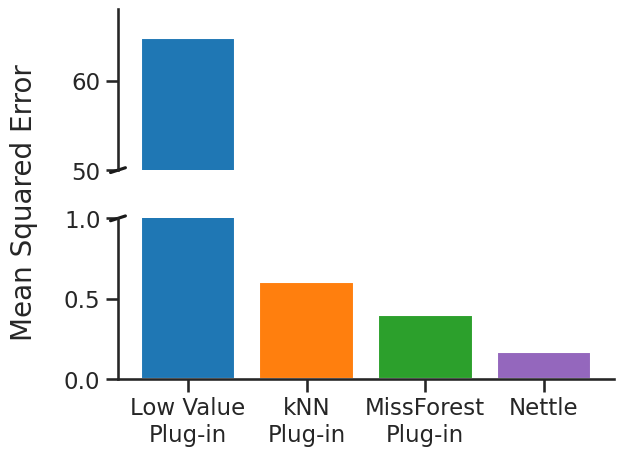

In [20]:
f, (ax_top, ax_bottom) = plt.subplots(ncols=1, nrows=2, sharex=True, gridspec_kw={'hspace':0.3})

sns.barplot(plotter1, x="method", y="MSE", palette=cmap_cust, saturation=1.0, legend=False, ax=ax_top)
sns.barplot(plotter1, x="method", y="MSE", palette=cmap_cust, saturation=1.0, legend=False, ax=ax_bottom)

ax_top.set_ylim(bottom=50)
ax_bottom.set_ylim(0,1)

sns.despine(ax=ax_bottom)
sns.despine(ax=ax_top, bottom=True)

ax_bottom.set_xlabel("")
ax_top.set_ylabel("")
ax_bottom.set_ylabel("")

ax_top.tick_params(bottom=False)

ax_bottom.tick_params(axis='both', which='minor', labelsize=12)

d = .015  # how big to make the diagonal lines in axes coordinates
# arguments to pass to plot, just so we don't keep repeating them
kwargs = dict(transform=ax_top.transAxes, color='k', clip_on=False)
ax_top.plot((-d, +d), (-d, +d), **kwargs)        # top-left diagonal

kwargs.update(transform=ax_bottom.transAxes)  # switch to the bottom axes
ax_bottom.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # bottom-left diagonal

plt.text(-1.5, 1.1, 'Mean Squared Error', va='center', rotation='vertical', size=20)

plt.tight_layout()
#plt.show()
plt.savefig("../figures/SMTG-MNAR-holdout-benchmarking-fig-ensembled.pdf", bbox_inches="tight")